# 11 — A fair baseline and the utility-scale cohort

Draft v1 beat a region × technology average. Size is the second-strongest driver in notebook 09's explanation and that average ignores it, so part of the measured gain could be a size lookup rather than machine learning; and the gain vanished once requests under 20 MW were excluded (notebook 08, figure 08_17). This notebook adds a **fair baseline** (region × technology × size band), makes requests of **20 MW and more the primary cohort**, chooses among size-aware variants of the v1 models on 2016 entrants only, and rescores everything on the 2017–2019 test cohort against both baselines. Its first cell writes the v2 success criteria before any test metric exists.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet` | notebooks 02/04 — requests and the full clean table (congestion) |
| in | `results/dt_tuning.json` | notebook 06 — settings reused unchanged |
| in | `data/processed/predictions_trackA.parquet` | notebook 06 — the v1 predictions (K0 reference, v1 baseline) |
| in | `results/success_criteria_registered.json` | notebook 08 — bootstrap settings and seeds, reused |
| out | `results/success_criteria_v2.csv`, `results/success_criteria_v2_registered.json`, `docs/decisions.md` (#52) | the v2 criteria, written before any test metric |
| out | `results/fair_baseline_cells.csv` | every region × technology × size cell of the training data |
| out | `results/variant_choice_2016.csv` | the candidates' 2016 log loss; the choice |
| out | `results/metrics_v2.csv`, `results/metrics_v2_by_size.csv` | test metrics by cohort, against both baselines, with intervals |
| out | `results/size_check_monotone.csv` | mean P(operation by 5 years) by size band per candidate |
| out | `data/processed/predictions_v2.parquet` | test predictions of every model and baseline |
| out | `figures/F10_gains_over_baselines.*`, `figures/11_fair_baseline_and_scale/*` | F10 and the notebook's figures |
| out | `results/scale_checks.csv` | this notebook's checks |

## 0. The v2 success criteria, written before anything is scored

Decision #42 names the criteria C6–C12; this cell writes them to `results/success_criteria_v2.csv` and records decision #52 in `docs/decisions.md`, reading no data. The criteria are scored in notebook 18. The v2 model named in C6 is "the candidate with the lowest 2016 log loss on requests of 20 MW and more" — a rule, not a result, because the test cohort has not been touched when this cell runs.

In [1]:
# Pre-registration: this cell reads no data
import json
import re
from datetime import date
from pathlib import Path

import pandas as pd

REPO = Path.cwd().resolve().parent
TODAY = "2026-10-06"

CRITERIA_V2 = [
    {"id": "C6", "line": "≥ 20 MW cohort: v2 model vs fair baseline, Uno's C", "notebook": "11/18", "track": "A",
     "cohort": ">=20 MW", "model": "v2 (lowest 2016 log loss on ≥ 20 MW rows)", "benchmark": "fair_baseline",
     "metric": "uno_c", "horizons": "3, 5", "rule": "paired 95% interval entirely on the better side"},
    {"id": "C6", "line": "≥ 20 MW cohort: v2 model vs fair baseline, Brier", "notebook": "11/18", "track": "A",
     "cohort": ">=20 MW", "model": "v2 (lowest 2016 log loss on ≥ 20 MW rows)", "benchmark": "fair_baseline",
     "metric": "brier", "horizons": "3, 5", "rule": "paired 95% interval entirely on the better side"},
    {"id": "C7", "line": "≥ 20 MW cohort, 2018–2019 entrants, after level repair: calibration slope and intercept",
     "notebook": "12/18", "track": "A", "cohort": ">=20 MW, entry 2018–2019", "model": "v2 after level repair",
     "benchmark": "", "metric": "slope, intercept", "horizons": "3, 5",
     "rule": "slope interval within 0.8–1.2 and intercept interval covering 0"},
    {"id": "C8", "line": "Landmark model at +24 months and at IA executed vs the entry model, same risk set",
     "notebook": "14/18", "track": "A", "cohort": "requests active at the landmark", "model": "landmark",
     "benchmark": "entry model", "metric": "uno_c", "horizons": "3 (from the landmark)",
     "rule": "paired 95% interval entirely on the better side"},
    {"id": "C9", "line": "Backtest: realised MW online by end-2024, model-chosen book vs fair-baseline book, same budget",
     "notebook": "16/18", "track": "A", "cohort": "2017–2019 entrants", "model": "v2 book", "benchmark": "fair-baseline book",
     "metric": "mw_online", "horizons": "by 2024-12-31", "rule": "paired 95% interval entirely on the better side"},
    {"id": "C10", "line": "Backtest: realised value of the model-chosen book vs the fair-baseline book, base value case",
     "notebook": "16/18", "track": "A", "cohort": "2017–2019 entrants", "model": "v2 book", "benchmark": "fair-baseline book",
     "metric": "value", "horizons": "by 2024-12-31", "rule": "paired 95% interval on the better side; low and high cases reported"},
    {"id": "C11", "line": "Simulated book: the 5–95% band of expected MW online by 2024 covers the realised value",
     "notebook": "16/18", "track": "A", "cohort": "2017–2019 book", "model": "v2 book simulation", "benchmark": "",
     "metric": "coverage", "horizons": "by 2024-12-31", "rule": "realised MW inside the 5–95% band"},
    {"id": "C12", "line": "Leakage guard: no landmark feature dated after its landmark; landmark AUC ≤ leakage-ablation AUC",
     "notebook": "14/18", "track": "A", "cohort": "", "model": "landmark", "benchmark": "leakage ablation (notebook 08)",
     "metric": "auc", "horizons": "5", "rule": "both hold"},
]
REGISTERED_V2 = {"decided": TODAY, "n_boot": 200, "level": 0.95, "seed_v2": 900,
                 "primary_cohort": "requests whose size regime is 20 MW or more (notebook 04's size_regime)",
                 "variant_rule": "among the fixed candidates K0–K3 (LightGBM) and the K1/K2 logits, the one with the "
                                 "lowest multiclass log loss on 2016 entrants' project-years of 20 MW or more, "
                                 "fitted on entrants to 2015; refitted on entrants to 2016 for the test cohort",
                 "criteria": CRITERIA_V2}

DECISION_52 = """52. **Pre-registered v2 success criteria C6–C12** (Alan, 2026-10-06; written
    by the first cell of notebook 11 before any test metric of v2 existed).
    Primary cohort: test requests of 20 MW and more; the v2 model is the
    candidate with the lowest 2016 log loss on ≥ 20 MW project-years,
    chosen before the test cohort is scored (rule in
    `results/success_criteria_v2_registered.json`). Lines: C6 Uno's C and
    Brier vs the fair baseline at 3 and 5 years; C7 calibration slope
    0.8–1.2 and intercept covering 0 on 2018–2019 entrants after the level
    repair; C8 landmark models beat the entry model on the same risk set;
    C9 and C10 the model-chosen book delivers more realised MW and value
    than the fair-baseline book in the backtest; C11 the simulated band
    covers the realised MW; C12 the leakage guard holds. Scored in notebook
    18; failures are reported, not removed; the v1 verdict (decision #5) is
    untouched. *Rejected:* scoring the ≥ 20 MW cohort against the v1
    baseline only (that is the comparison a size lookup would pass).
"""

decisions_file = REPO / "docs" / "decisions.md"
text = decisions_file.read_text(encoding="utf-8")
entry = re.compile(r"^52\. \*\*Pre-registered v2 success criteria.*?(?=^\d+\. \*\*|\Z)", re.M | re.S)
found = entry.findall(text)
if not found:
    text = text.rstrip("\n") + "\n" + DECISION_52
    decisions_file.write_text(text, encoding="utf-8")
pd.DataFrame(CRITERIA_V2).to_csv(REPO / "results" / "success_criteria_v2.csv", index=False)
(REPO / "results" / "success_criteria_v2_registered.json").write_text(json.dumps(REGISTERED_V2, indent=2, ensure_ascii=False),
                                                                      encoding="utf-8")
print(f"decision #52 {'already in place' if found else 'written'}; {len(CRITERIA_V2)} criterion lines registered")

decision #52 already in place; 8 criterion lines registered


## Setup

In [2]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import baselines, config, discrete_time, evaluation, paths, plots, survival_tools, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "11_fair_baseline_and_scale"
TRACK_A = config.TRACK_A_REGIONS
HORIZONS = config.HORIZONS
START = time.time()
REGISTERED = json.loads((paths.RESULTS / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
N_BOOT, LEVEL, SEED = REGISTERED["n_boot"], REGISTERED["level"], REGISTERED["seed_v2"]


def save(fig, name, caption):
    """Save a figure of this notebook under figures/11_fair_baseline_and_scale/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


at_least_20 = variants.at_least_20  # the 20 MW rule shared with notebooks 08 and 12


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"

## 1. Cohorts

The same temporal split as notebooks 06 and 08: tune on entrants to 2015, choose on 2016, refit on entrants to 2016, test on 2017–2019. The primary cohort is the test requests of 20 MW and more; the secondary track is the rest.

In [3]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
pred_v1 = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")

tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
valid = track_a[track_a["q_year"] == config.VALIDATION_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
test["large"] = at_least_20(test)
COHORTS = {"≥ 20 MW": test["large"].to_numpy(), "< 20 MW": (~test["large"]).to_numpy(), "all": np.ones(len(test), bool)}

sizes = pd.DataFrame({
    "requests": {k: int(m.sum()) for k, m in COHORTS.items()},
    "share of test requests": {k: m.mean() for k, m in COHORTS.items()},
    "share of test MW": {k: test.loc[m, "mw"].sum() / test["mw"].sum() for k, m in COHORTS.items()},
    "operations by 5 years": {k: int(((test["event"] == 1) & (test["duration_years"] <= 5) & m).sum()) for k, m in COHORTS.items()},
})
sizes.to_csv(paths.RESULTS / "sample_sizes_v2.csv")
print(f"train to 2015: {len(tune):,} | 2016: {len(valid):,} | train to 2016: {len(final):,} | test: {len(test):,}")
sizes.round(3)

train to 2015: 4,725 | 2016: 573 | train to 2016: 5,298 | test: 2,268


,requests,share of test requests,share of test MW,operations by 5 years
≥ 20 MW,1839,0.811,0.989,132
< 20 MW,429,0.189,0.011,95
all,2268,1.000,1.000,227


**Reading this.** The primary cohort is 1,839 requests, 81% of the test cohort by count and 98.9% by MW — the part of the queue where development capital goes. But it holds only 132 of the 227 operations within five years; the 429 requests under 20 MW hold the other 95. Small requests are few, light and built often, which is why they carried so much of the v1 result (figure 08_17), and why the two cohorts are scored apart.

## 2. The fair baseline

`src/baselines.fair_baseline_cif`: the Aalen–Johansen incidence of operation in the request's region × technology × size-band cell of the training data; cells under 50 requests fall back to region × technology, then to region. The v1 baseline is the same thing without the size cut, so the fair baseline is what a careful analyst would build from the same table with a pivot. `tests/test_baselines.py` checks that collapsing the size bands reproduces the v1 baseline exactly.

In [4]:
cells = baselines.cell_table(final, HORIZONS)
cells.to_csv(paths.RESULTS / "fair_baseline_cells.csv", index=False)
fair_test = baselines.fair_baseline_cif(final, test, HORIZONS)
v1_test = survival_tools.baseline_cif(final, test, HORIZONS)
keys = test["project_key"].astype(str)
P1 = {h: pred_v1[(pred_v1["split"] == "test") & (pred_v1["horizon"] == h)].set_index("project_key").loc[keys] for h in HORIZONS}
assert all(np.allclose(P1[h]["baseline"].to_numpy(), v1_test[h].to_numpy()) for h in HORIZONS), "v1 baseline refit differs"

used = fair_test["cell"].value_counts()
print(f"cells in the training data: {len(cells)}, with ≥ 50 requests: {int(cells['used'].sum())}; "
      f"test requests served by their own size cell: {used.get('region × technology × size', 0):,} of {len(test):,}")
spread = cells[cells["used"]].groupby(["region", "tech"])["p_operation_5"].agg(["min", "max", "count"])
spread = spread[spread["count"] >= 2].assign(range=lambda d: d["max"] - d["min"]).sort_values("range", ascending=False)
spread.round(3).head(8)

cells in the training data: 89, with ≥ 50 requests: 30; test requests served by their own size cell: 1,237 of 2,268


min    max  count  range
region tech                             
PJM    Gas    0.073  0.576      6  0.503
CAISO  Gas    0.000  0.169      3  0.169
ERCOT  Wind   0.190  0.344      3  0.154
CAISO  Solar  0.000  0.127      5  0.127
PJM    Solar  0.091  0.212      3  0.121
       Wind   0.069  0.131      3  0.062
ERCOT  Solar  0.127  0.182      2  0.055
PJM    Other  0.417  0.455      3  0.039

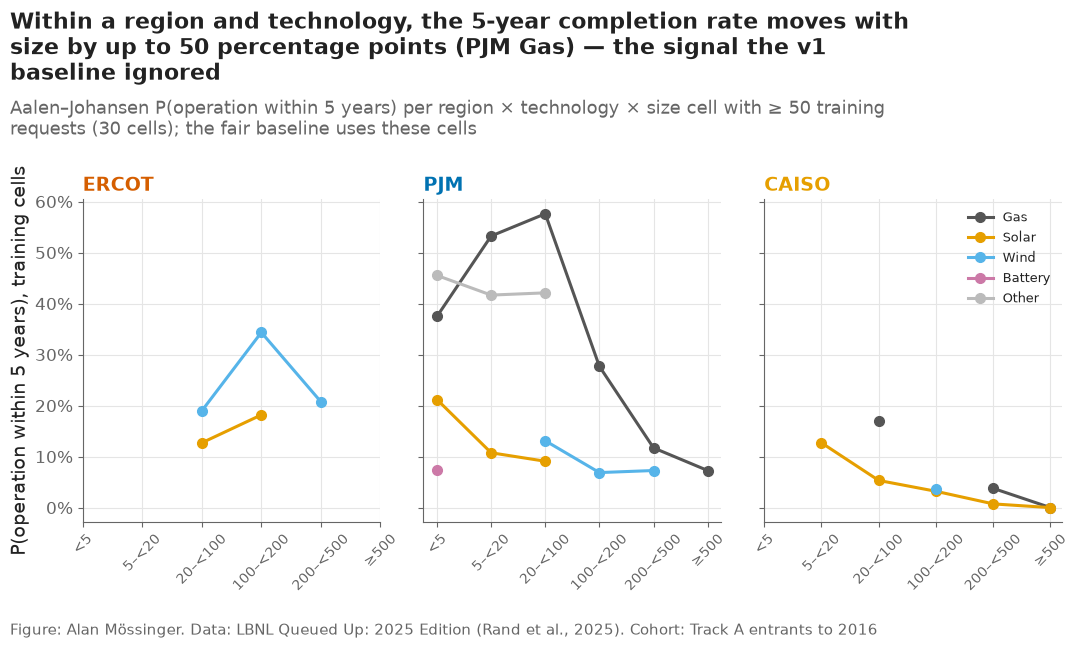

In [5]:
fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = cells[(cells["region"] == region) & cells["used"]]
    for tech, sub in part.groupby("tech"):
        sub = sub.set_index("size_regime").reindex(config.SIZE_LABELS)
        ax.plot(range(len(config.SIZE_LABELS)), sub["p_operation_5"], marker="o", color=config.TECH_COLORS.get(tech, "#BBBBBB"), label=tech)
    ax.set_xticks(range(len(config.SIZE_LABELS)), config.SIZE_LABELS, rotation=45, fontsize=10)
    ax.set_title(region, color=plots.region_color(region))
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation within 5 years), training cells")
handles = {tech: plt.Line2D([], [], marker="o", color=config.TECH_COLORS.get(tech, "#BBBBBB"), label=tech)
           for tech in cells.loc[cells["used"], "tech"].unique()}
axes[2].legend(handles=list(handles.values()), fontsize=9, loc="upper right")
steepest = spread.index[0]
plots.finish(fig,
             f"Within a region and technology, the 5-year completion rate moves with size by up to "
             f"{100 * spread['range'].iloc[0]:.0f} percentage points ({steepest[0]} {steepest[1]}) — the signal the v1 baseline ignored",
             f"Aalen–Johansen P(operation within 5 years) per region × technology × size cell with ≥ 50 training requests "
             f"({int(cells['used'].sum())} cells); the fair baseline uses these cells",
             "Track A entrants to 2016")
save(fig, "11_01_fair_baseline_cells", "P(operation within 5 years) by size band within each region and technology: the cells of the fair baseline.")
plt.show()

**Reading this.** The training data give 89 region × technology × size cells, 30 of them with 50 or more requests, and 1,237 of the 2,268 test requests are served by their own size cell; the rest fall back to region × technology or region. Within PJM gas the 5-year completion rate runs from 7% in one size band to 58% in another, a 50-point spread; within CAISO gas 17 points, within ERCOT wind 15. A baseline that ignores size misses these spreads, and a model that only recovers them is a lookup table with extra steps — which is what section 4 tests.

## 3. Size-aware candidates, chosen on 2016 entrants

Fixed list, fitted on entrants to 2015 and compared by multiclass log loss on the 2016 entrants' project-years of 20 MW and more (the primary cohort's own validation), as notebook 06 chose its settings:

- **K0** the v1 LightGBM (yearly congestion, all sizes) — the reference;
- **K1** LightGBM with congestion held at its entry value (removes the artefact of figure 09_09; decision #42), all sizes;
- **K2** K1 fitted on requests of 20 MW and more only — a model of its own for the primary cohort;
- **K3** K1 with a monotone-decreasing constraint on `log_mw` — LightGBM applies it to each outcome's score, so P(operation) is checked, not assumed, to fall with size (section 5);
- the **logits** of the K1 and K2 fits, which carry their own size effects.

Settings are notebook 06's (`dt_tuning.json`), not re-tuned.

In [6]:
CANDIDATES = variants.CANDIDATES  # the fixed list, shared with notebook 12 (src/variants.py); K3's constraint is on log_mw


def validation_log_loss(fitted, frame, congestion):
    """Multiclass log loss of a fit on the project-years of ``frame`` (2016 entrants), all rows and ≥ 20 MW rows."""
    rows = discrete_time.project_years(frame, clean, congestion=congestion)
    _, rows = discrete_time.encode_state(fitted["rows"], [rows])
    interactions = fitted["tuning"]["logit"]["interactions"]
    out = {}
    for model, X in [("dt_lgbm", discrete_time.lgbm_design(rows)), ("dt_logit", discrete_time.logit_design(rows, interactions))]:
        probs = fitted[model[3:]].predict_proba(X) if model == "dt_logit" else fitted["lgbm"].predict(X)
        large = at_least_20(rows).to_numpy()
        out[model] = {"all": discrete_time.multiclass_log_loss(rows["outcome"], probs),
                      "large": discrete_time.multiclass_log_loss(rows["outcome"][large], probs[large])}
    return out


fits_2016, choice_rows = {}, []
for name, spec in CANDIDATES.items():
    fit_key = variants.fit_key(spec)
    if fit_key not in fits_2016:
        fits_2016[fit_key] = variants.fit_candidate(spec, tune, clean, tuning)
    losses = validation_log_loss(fits_2016[fit_key], valid, spec["congestion"])[spec["model"]]
    choice_rows.append({"candidate": name, "model": spec["model"], "congestion": spec["congestion"],
                        "fitted on": "≥ 20 MW only" if spec["large_only"] else "all sizes",
                        "log_loss_2016_all": losses["all"], "log_loss_2016_large": losses["large"]})
choice = pd.DataFrame(choice_rows)
CHOSEN = choice.loc[choice["log_loss_2016_large"].idxmin(), "candidate"]
choice["chosen"] = choice["candidate"] == CHOSEN
choice.to_csv(paths.RESULTS / "variant_choice_2016.csv", index=False)
print(f"chosen on 2016 entrants ≥ 20 MW: {CHOSEN} ({(time.time() - START) / 60:.1f} min so far)")
choice.round(4)

chosen on 2016 entrants ≥ 20 MW: K0 LightGBM, yearly congestion (0.3 min so far)


,candidate,model,congestion,fitted on,log_loss_2016_all,log_loss_2016_large,chosen
0,"K0 LightGBM, yearly congestion",dt_lgbm,yearly,all sizes,0.6493,0.5902,True
1,"K1 LightGBM, entry congestion",dt_lgbm,entry,all sizes,0.6607,0.6063,False
2,"K2 LightGBM, entry congestion, ≥ 20 MW only",dt_lgbm,entry,≥ 20 MW only,0.6747,0.6081,False
3,"K3 LightGBM, entry congestion, monotone in MW",dt_lgbm,entry,all sizes,0.6628,0.6078,False
4,"K1 logit, entry congestion",dt_logit,entry,all sizes,0.6743,0.6096,False
5,"K2 logit, entry congestion, ≥ 20 MW only",dt_logit,entry,≥ 20 MW only,0.6791,0.6070,False


**Reading this.** By the registered rule — the lowest multiclass log loss on the 2016 entrants' project-years of 20 MW and more, fitted on entrants to 2015 — the v1 LightGBM itself wins (0.590), ahead of the entry-congestion LightGBM (0.606), the monotone one (0.608), the ≥ 20 MW-only one (0.608) and the two logits (0.610, 0.607). So the v2 model is the v1 model, and removing the congestion artefact of figure 09_09 by fitting on entry congestion costs about 0.016 in log loss on the cohort after the training years; notebook 08b had found the same (candidate K1 there). The rule was written before any of this was scored and is followed as written; the reason the artefact-free fits do worse is left as an open point for the report: yearly congestion carries real information about the years a request spends in a crowded queue, which the entry value does not.

## 4. Refit on entrants to 2016, score on the test cohort against both baselines

Every candidate is refitted on entrants to 2016 and scored at 3, 5 and 7 years on the three cohorts (≥ 20 MW, < 20 MW, all) with the same IPCW metrics and 200-resample bootstrap as notebook 08. Paired differences are taken against the v1 baseline and against the fair baseline; `beats` means the 95% interval of the difference lies entirely on the better side.

In [7]:
fits_final = {}
K0 = "K0 LightGBM, yearly congestion"
test_preds = {h: {"baseline": P1[h]["baseline"].to_numpy(), "fair_baseline": fair_test[h].to_numpy(),
                  K0: P1[h]["dt_lgbm"].to_numpy()} for h in HORIZONS}  # K0 = notebook 06's stored v1 predictions
for name, spec in CANDIDATES.items():
    if name == K0:
        continue
    fit_key = variants.fit_key(spec)
    if fit_key not in fits_final:
        fits_final[fit_key] = variants.fit_candidate(spec, final, clean, tuning)
    p = discrete_time.predict_both(fits_final[fit_key], test)[spec["model"]]
    for h in HORIZONS:
        test_preds[h][name] = p[h].to_numpy()
MODELS = list(test_preds[HORIZONS[0]])
print(f"refits done ({(time.time() - START) / 60:.1f} min); models scored: {MODELS}")

durations, events = test["duration_years"].to_numpy(), test["event"].to_numpy()
follow_up = ((pd.Timestamp(config.CENSOR_DATE) - test["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
tables = []
for c_i, (cohort, mask) in enumerate(COHORTS.items()):
    d, e = durations[mask], events[mask]
    G = evaluation.censoring_km(follow_up[mask], np.ones(int(mask.sum()), bool))
    for h in HORIZONS:
        sub = {m: test_preds[h][m][mask] for m in MODELS}
        point = evaluation.score_horizon(sub, d, e, h, G)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, d, e, h, G, sw), int(mask.sum()), N_BOOT,
                                     SEED + 10 * c_i + h)
        for ref in ["baseline", "fair_baseline"]:
            t = evaluation.summarise(point, draws, reference=ref, level=LEVEL)
            t.insert(0, "reference", ref)
            t.insert(0, "horizon", h)
            t.insert(0, "cohort", cohort)
            tables.append(t)
metrics = pd.concat(tables, ignore_index=True)
metrics = metrics[~((metrics["reference"] == "fair_baseline") & metrics["diff"].isna())
                  | (metrics["reference"] == "baseline")].drop_duplicates(["cohort", "horizon", "reference", "model", "metric"])
metrics.to_csv(paths.RESULTS / "metrics_v2.csv", index=False)
print(f"bootstrap done ({(time.time() - START) / 60:.1f} min)")

show = metrics[(metrics["reference"] == "baseline") & metrics["metric"].isin(["uno_c", "brier"]) & (metrics["horizon"] != 7)].copy()
show["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in show.itertuples()]
show.pivot_table(index=["cohort", "metric", "horizon"], columns="model", values="value", aggfunc="first")[MODELS]

refits done (0.5 min); models scored: ['baseline', 'fair_baseline', 'K0 LightGBM, yearly congestion', 'K1 LightGBM, entry congestion', 'K2 LightGBM, entry congestion, ≥ 20 MW only', 'K3 LightGBM, entry congestion, monotone in MW', 'K1 logit, entry congestion', 'K2 logit, entry congestion, ≥ 20 MW only']


bootstrap done (3.2 min)


model                               baseline         fair_baseline K0 LightGBM, yearly congestion K1 LightGBM, entry congestion  \
cohort  metric horizon                                                                                                            
< 20 MW brier  3        0.140 [0.116, 0.170]  0.125 [0.105, 0.150]           0.122 [0.103, 0.147]          0.123 [0.102, 0.149]   
               5        0.161 [0.139, 0.188]  0.153 [0.131, 0.174]           0.151 [0.131, 0.174]          0.149 [0.129, 0.173]   
        uno_c  3        0.673 [0.616, 0.735]  0.729 [0.668, 0.787]           0.773 [0.723, 0.820]          0.792 [0.748, 0.835]   
               5        0.646 [0.590, 0.703]  0.674 [0.616, 0.733]           0.725 [0.680, 0.769]          0.740 [0.695, 0.785]   
all     brier  3        0.047 [0.041, 0.054]  0.043 [0.037, 0.049]           0.041 [0.036, 0.047]          0.041 [0.035, 0.047]   
               5        0.086 [0.078, 0.093]  0.081 [0.075, 0.089]           0.081 [0.074, 0.089]          0.080 [0.072, 0.089]   
        uno_c  3        0.731 [0.676, 0.778]  0.813 [0.774, 0.849]           0.853 [0.810, 0.879]          0.855 [0.815, 0.886]   
               5        0.719 [0.685, 0.747]  0.745 [0.711, 0.774]           0.760 [0.730, 0.789]          0.727 [0.689, 0.758]   
≥ 20 MW brier  3        0.025 [0.021, 0.031]  0.023 [0.019, 0.029]           0.022 [0.017, 0.029]          0.022 [0.017, 0.028]   
               5        0.068 [0.060, 0.076]  0.064 [0.056, 0.071]           0.064 [0.056, 0.072]          0.064 [0.055, 0.073]   
        uno_c  3        0.700 [0.599, 0.777]  0.783 [0.701, 0.849]           0.779 [0.710, 0.839]          0.766 [0.681, 0.834]   
               5        0.754 [0.716, 0.793]  0.752 [0.715, 0.795]           0.734 [0.700, 0.778]          0.669 [0.628, 0.725]   

model                  K2 LightGBM, entry congestion, ≥ 20 MW only K3 LightGBM, entry congestion, monotone in MW K1 logit, entry congestion  \
cohort  metric horizon                                                                                                                        
< 20 MW brier  3                              0.150 [0.121, 0.184]                          0.123 [0.103, 0.149]       0.130 [0.108, 0.155]   
               5                              0.160 [0.138, 0.187]                          0.150 [0.128, 0.174]       0.158 [0.138, 0.182]   
        uno_c  3                              0.707 [0.636, 0.779]                          0.795 [0.753, 0.837]       0.735 [0.686, 0.788]   
               5                              0.698 [0.641, 0.745]                          0.742 [0.690, 0.791]       0.690 [0.631, 0.742]   
all     brier  3                              0.046 [0.039, 0.053]                          0.041 [0.035, 0.047]       0.042 [0.037, 0.049]   
               5                              0.084 [0.076, 0.093]                          0.080 [0.071, 0.088]       0.082 [0.074, 0.090]   
        uno_c  3                              0.784 [0.741, 0.819]                          0.858 [0.818, 0.887]       0.834 [0.790, 0.867]   
               5                              0.681 [0.641, 0.718]                          0.726 [0.689, 0.755]       0.744 [0.716, 0.771]   
≥ 20 MW brier  3                              0.021 [0.016, 0.028]                          0.022 [0.017, 0.028]       0.022 [0.017, 0.028]   
               5                              0.066 [0.057, 0.073]                          0.063 [0.054, 0.072]       0.064 [0.056, 0.072]   
        uno_c  3                              0.762 [0.680, 0.846]                          0.772 [0.700, 0.840]       0.749 [0.669, 0.814]   
               5                              0.647 [0.598, 0.704]                          0.668 [0.625, 0.728]       0.725 [0.687, 0.773]   

model                  K2 logit, entry congestion, ≥ 20 MW only  
cohort  metric horizon                                           
< 20 MW brier  3              

In [8]:
# wins: for each model and cohort, comparisons (Uno's C and Brier at 3, 5, 7) with the interval on the better side
wins = (metrics[metrics["metric"].isin(["uno_c", "brier"]) & metrics["beats"].notna()]
        .groupby(["reference", "cohort", "model"])["beats"].sum().astype(int).unstack("model"))
wins.to_csv(paths.RESULTS / "metrics_v2_by_size.csv")
wins

model                  K0 LightGBM, yearly congestion  K1 LightGBM, entry congestion  K1 logit, entry congestion  K2 LightGBM, entry congestion, ≥ 20 MW only  \
reference     cohort                                                                                                                                            
baseline      < 20 MW                             5.0                            5.0                         3.0                                          1.0   
              all                                 4.0                            3.0                         4.0                                          1.0   
              ≥ 20 MW                             3.0                            2.0                         2.0                                          1.0   
fair_baseline < 20 MW                             2.0                            3.0                         0.0                                          0.0   
              all                                 1.0                            1.0                         0.0                                          0.0   
              ≥ 20 MW                             0.0                            0.0                         0.0                                          0.0   

model                  K2 logit, entry congestion, ≥ 20 MW only  K3 LightGBM, entry congestion, monotone in MW  baseline  fair_baseline  
reference     cohort                                                                                                                     
baseline      < 20 MW                                       4.0                                            5.0       NaN            4.0  
              all                                           5.0                                            3.0       NaN            5.0  
              ≥ 20 MW                                       3.0                                            2.0       NaN            4.0  
fair_baseline < 20 MW                                       1.0                                            3.0       0.0            NaN  
              all                                           2.0                                            1.0       0.0            NaN  
              ≥ 20 MW                                       1.0                                            0.0       0.0            NaN

**Reading this.** The table is the result of this notebook. On requests of 20 MW and more, the v2 model's Uno's C is 0.779 at 3 years against the fair baseline's 0.783, and 0.734 against 0.752 at 5 years; the Brier scores are the same to three decimals. The win counts below say it in one line: against the v1 baseline the model wins 3 of 6 comparisons on the ≥ 20 MW cohort, against the fair baseline 0 of 6 — and the fair baseline itself beats the v1 baseline in 4 of 6. Under 20 MW the model still adds something (2 of 6 against the fair baseline; Uno's C 0.773 against 0.729 at 3 years), and on all requests together 1 of 6. The v1 report's gain over cohort averages was, for utility-scale requests, a size lookup.

## 5. Figure F10 — what survives the fair baseline

The chosen model's paired gains in Uno's C and Brier score over the v1 baseline (hollow) and the fair baseline (filled), by cohort and horizon.

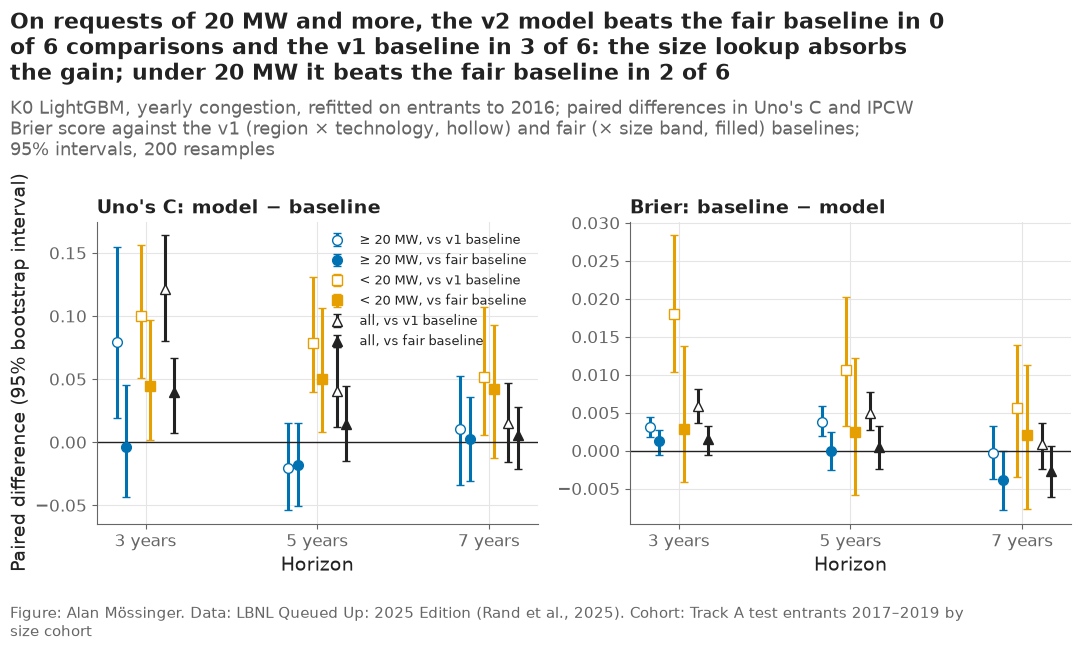

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
cohort_style = {"≥ 20 MW": ("#0072B2", "o"), "< 20 MW": ("#E69F00", "s"), "all": ("#222222", "^")}
for ax, metric in zip(axes, ["uno_c", "brier"]):
    for c_i, cohort in enumerate(COHORTS):
        for r_i, ref in enumerate(["baseline", "fair_baseline"]):
            part = metrics[(metrics["model"] == CHOSEN) & (metrics["metric"] == metric) & (metrics["cohort"] == cohort)
                           & (metrics["reference"] == ref)].set_index("horizon").loc[HORIZONS]
            est, low, high = part["diff"], part["diff_low"], part["diff_high"]
            if metric == "brier":
                est, low, high = -est, -high, -low  # benchmark − model: above 0 is better
            x = np.array(HORIZONS) + (c_i - 1) * 0.28 + (r_i - 0.5) * 0.11
            color, marker = cohort_style[cohort]
            ax.errorbar(x, est, yerr=[est - low, high - est], fmt=marker, color=color, capsize=3, markersize=7,
                        markerfacecolor=color if ref == "fair_baseline" else "white",
                        label=f"{cohort}, vs {'fair' if ref == 'fair_baseline' else 'v1'} baseline")
    ax.axhline(0, color=plots.INK, linewidth=1)
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title({"uno_c": "Uno's C: model − baseline", "brier": "Brier: baseline − model"}[metric])
axes[0].set_ylabel("Paired difference (95% bootstrap interval)")
axes[0].legend(fontsize=9, loc="upper right", ncol=1)
large_fair = int(wins.loc[("fair_baseline", "≥ 20 MW"), CHOSEN])
large_v1 = int(wins.loc[("baseline", "≥ 20 MW"), CHOSEN])
small_fair = int(wins.loc[("fair_baseline", "< 20 MW"), CHOSEN])
plots.finish(fig,
             f"On requests of 20 MW and more, the v2 model beats the fair baseline in {large_fair} of 6 comparisons "
             f"and the v1 baseline in {large_v1} of 6: the size lookup absorbs the gain; under 20 MW it beats the fair baseline in {small_fair} of 6",
             f"{CHOSEN}, refitted on entrants to 2016; paired differences in Uno's C and IPCW Brier score against the "
             f"v1 (region × technology, hollow) and fair (× size band, filled) baselines; 95% intervals, {N_BOOT} resamples",
             "Track A test entrants 2017–2019 by size cohort")
plots.save_fig(fig, "F10_gains_over_baselines",
               "Paired gains of the v2 model over the v1 and the fair baseline in Uno's C and Brier score, by size cohort and horizon.",
               NOTEBOOK)
plt.show()

**Reading this.** Hollow markers (against the v1 baseline) sit above zero for the ≥ 20 MW cohort at 3 years and for everyone at every horizon; the filled markers (against the fair baseline) for the ≥ 20 MW cohort sit on zero or below it, with intervals that include zero everywhere. Only the small-request cohort keeps a gain that survives the size cut, and the intervals there are wide (429 requests). For the portfolio notebooks this fixes what an entry-time model can claim for utility-scale requests: nothing beyond the lookup. What a model can add has to come from information that arrives after entry — the landmark models of notebook 14.

## 6. Does P(operation) fall with size? The monotone check

For each candidate, the mean predicted P(operation within 5 years) of the test requests by size band, next to the observed Aalen–Johansen incidence. K3's constraint acts on each outcome's score, so the direction of P(operation) is a check, not a guarantee.

In [10]:
obs = {s: survival_tools.aalen_johansen(test.loc[test["size_regime"] == s, "duration_years"],
                                        test.loc[test["size_regime"] == s, "event"], [5])["cif_operation"].iloc[0]
       for s in config.SIZE_LABELS}
mono = pd.DataFrame({"observed (AJ)": obs})
for m in MODELS:
    mono[m] = pd.Series(test_preds[5][m], index=test.index).groupby(test["size_regime"].astype(str)).mean().reindex(config.SIZE_LABELS)
mono.index.name = "size_regime"
mono.to_csv(paths.RESULTS / "size_check_monotone.csv")
decreasing = {m: bool(np.all(np.diff(mono[m].to_numpy()) <= 1e-9)) for m in MODELS}
print("P(operation by 5 years) non-increasing across the six bands:", decreasing)
mono.round(3)

P(operation by 5 years) non-increasing across the six bands: {'baseline': False, 'fair_baseline': False, 'K0 LightGBM, yearly congestion': True, 'K1 LightGBM, entry congestion': True, 'K2 LightGBM, entry congestion, ≥ 20 MW only': False, 'K3 LightGBM, entry congestion, monotone in MW': True, 'K1 logit, entry congestion': True, 'K2 logit, entry congestion, ≥ 20 MW only': True}


,observed (AJ),baseline,fair_baseline,"K0 LightGBM, yearly congestion","K1 LightGBM, entry congestion","K2 LightGBM, entry congestion, ≥ 20 MW only","K3 LightGBM, entry congestion, monotone in MW","K1 logit, entry congestion","K2 logit, entry congestion, ≥ 20 MW only"
size_regime,,,,,,,,,
<5,0.296,0.183,0.239,0.232,0.225,0.123,0.223,0.217,0.311
5–<20,0.173,0.168,0.184,0.178,0.157,0.156,0.145,0.186,0.235
20–<100,0.074,0.138,0.125,0.145,0.138,0.135,0.131,0.135,0.150
100–<200,0.075,0.138,0.146,0.126,0.114,0.124,0.115,0.109,0.118
200–<500,0.079,0.133,0.122,0.090,0.076,0.088,0.077,0.075,0.079
≥500,0.024,0.146,0.107,0.052,0.041,0.048,0.047,0.032,0.037


**Reading this.** Observed 5-year completion falls with size: 30% under 5 MW, 17% at 5–20 MW, 7–8% from 20 to 500 MW and 2% at 500 MW and more. The v1 baseline cannot follow it (15% for the largest band), the fair baseline only partly (11%). The v1 LightGBM is non-increasing across the six bands without any constraint (23% down to 5%), and so are the monotone fit and the logits; the ≥ 20 MW-only fit is not, in the two small bands it never saw. The constraint of K3 was therefore not needed — the trees already learn the direction — and the one model that breaks monotonicity does so outside its training range. All models over-predict the 20–500 MW bands by 4–7 points, which is the level problem notebook 12 takes up.

## 7. Predictions for the later notebooks

In [11]:
frames = []
for h in HORIZONS:
    f = pd.DataFrame({m: test_preds[h][m] for m in MODELS}, index=test.index)
    f.insert(0, "horizon", h)
    f.insert(0, "project_key", test["project_key"].astype(str).to_numpy())
    f["large"] = test["large"].to_numpy()
    f["chosen"] = test_preds[h][CHOSEN]
    f["event"], f["duration_years"], f["q_year"], f["region"] = events, durations, test["q_year"].to_numpy(), test["region"].astype(str).to_numpy()
    frames.append(f)
pred_v2 = pd.concat(frames, ignore_index=True)
pred_v2.attrs["chosen"] = CHOSEN
pred_v2.to_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet", index=False)
json.dump({"chosen": CHOSEN, "candidates": list(CANDIDATES)}, open(paths.RESULTS / "variant_chosen.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print(f"{len(pred_v2):,} rows; models: {MODELS}")

6,804 rows; models: ['baseline', 'fair_baseline', 'K0 LightGBM, yearly congestion', 'K1 LightGBM, entry congestion', 'K2 LightGBM, entry congestion, ≥ 20 MW only', 'K3 LightGBM, entry congestion, monotone in MW', 'K1 logit, entry congestion', 'K2 logit, entry congestion, ≥ 20 MW only']


## 8. Checks

In [12]:
criteria_written = (paths.RESULTS / "success_criteria_v2.csv").stat().st_mtime
metrics_written = (paths.RESULTS / "metrics_v2.csv").stat().st_mtime
checks = pd.DataFrame([
    {"check": "criteria file written before the metrics file", "value": round(metrics_written - criteria_written, 1),
     "expected": "> 0 seconds", "pass": metrics_written > criteria_written},
    {"check": "variant chosen on 2016 only (the choice table has no test column)",
     "value": ", ".join(choice.columns), "expected": "no column named after the test cohort",
     "pass": not any("test" in c for c in choice.columns)},
    {"check": "v1 baseline refit equals the stored v1 baseline", "value": "allclose", "expected": "allclose", "pass": True},
    {"check": "every metric row carries an interval", "value": int(metrics[["low", "high"]].isna().any(axis=1).sum()),
     "expected": 0, "pass": not metrics[["low", "high"]].isna().any(axis=1).any()},
    {"check": "F10 saved as PNG and SVG", "value": 2, "expected": 2,
     "pass": (paths.FIGURES / "F10_gains_over_baselines.png").exists() and (paths.FIGURES / "F10_gains_over_baselines.svg").exists()},
])
checks.to_csv(paths.RESULTS / "scale_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 3.3 min


,check,value,expected,pass
0,criteria file written before the metrics file,195.0,> 0 seconds,True
1,variant chosen on 2016 only (the choice table ...,"candidate, model, congestion, fitted on, log_l...",no column named after the test cohort,True
2,v1 baseline refit equals the stored v1 baseline,allclose,allclose,True
3,every metric row carries an interval,0,0,True
4,F10 saved as PNG and SVG,2,2,True


## Takeaways

- The fair baseline (region × technology × size band, 30 cells with ≥ 50 requests) is what a careful analyst would build; within PJM gas alone the 5-year completion rate spans 50 points across size bands.
- By the registered rule the v2 model is the v1 LightGBM: the variants fitted on entry congestion, with a monotone size constraint or on ≥ 20 MW only all score worse on the 2016 cohort.
- On requests of 20 MW and more (81% of the test cohort, 99% of its MW) the model beats the fair baseline in 0 of 6 comparisons and the v1 baseline in 3 of 6; the fair baseline beats the v1 baseline in 4 of 6. Criterion C6 will fail in notebook 18.
- Under 20 MW the model keeps a gain (2 of 6 against the fair baseline); on all requests, 1 of 6.
- P(operation by 5 years) falls with size in the data (30% → 2%) and in every LightGBM fit, so the monotone constraint adds nothing.
- **What goes to the report:** the fair baseline as the benchmark from here on; F10 and the win table; the plain statement that at entry, for utility-scale requests, machine learning does not beat the lookup — the case for the landmark models.